  IRIS FLOWER CLASSIFICATION

Dataset shape : (150, 5)
Classes       : ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']

First 5 rows:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0            5.1           3.5            1.4           0.2  Iris-setosa
1            4.9           3.0            1.4           0.2  Iris-setosa
2            4.7           3.2            1.3           0.2  Iris-setosa
3            4.6           3.1            1.5           0.2  Iris-setosa
4            5.0           3.6            1.4           0.2  Iris-setosa

Accuracy : 90.00%

Classification Report:
-------------------------------------------------------
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.82      0.90      0.86        10
 Iris-virginica       0.89      0.80      0.84        10

       accuracy                           0.90        30
      macro avg       0.90      0.90 

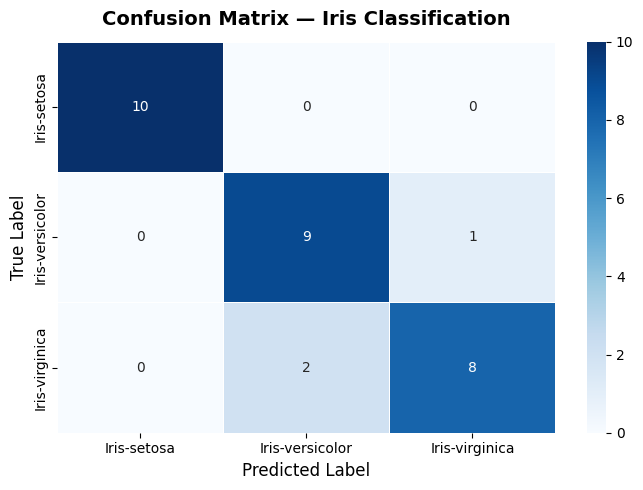

Confusion matrix saved → confusion_matrix.png


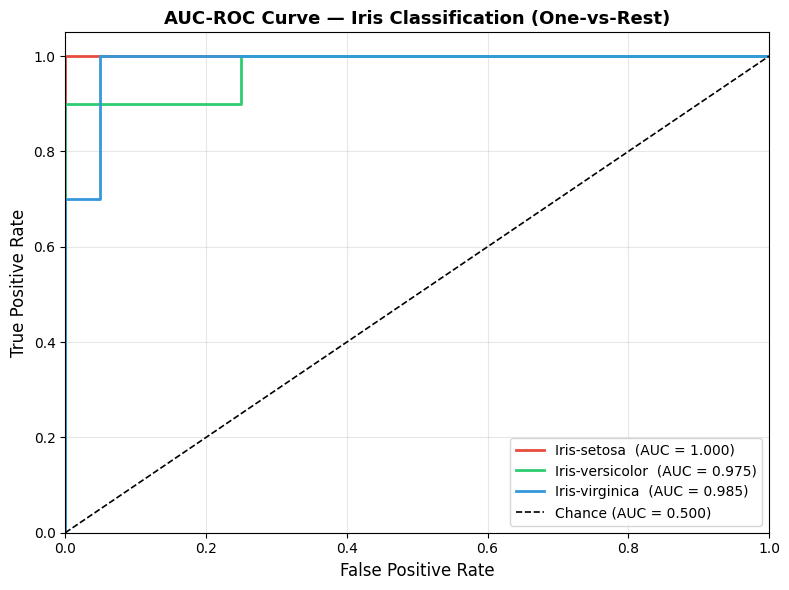

ROC curve saved → auc_roc_curve.png

Done! ✅


In [ ]:
# ============================================================
#   TASK 1 — Iris Flower Classification
#   Accuracy · Classification Report · Confusion Matrix · ROC
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
)

# ── 1. Load Dataset ──────────────────────────────────────────
df = pd.read_csv("Iris.csv")

# Drop the Id column if present
if "Id" in df.columns:
    df.drop(columns=["Id"], inplace=True)

print("=" * 55)
print("  IRIS FLOWER CLASSIFICATION")
print("=" * 55)
print(f"\nDataset shape : {df.shape}")
print(f"Classes       : {df['Species'].unique().tolist()}")
print(f"\nFirst 5 rows:\n{df.head()}\n")

# ── 2. Prepare Features & Labels ────────────────────────────
X = df.drop(columns=["Species"]).values
y = df["Species"].values

le = LabelEncoder()
y_encoded = le.fit_transform(y)          # 0, 1, 2
class_names = le.classes_               # ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
n_classes = len(class_names)

# ── 3. Train / Test Split ───────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# ── 4. Train Model ──────────────────────────────────────────
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# ── 5. Predict ──────────────────────────────────────────────
y_pred       = model.predict(X_test)
y_prob       = model.predict_proba(X_test)   # shape (n_samples, 3)

# ── 6. Accuracy ─────────────────────────────────────────────
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy : {accuracy * 100:.2f}%\n")

# ── 7. Classification Report ────────────────────────────────
print("Classification Report:")
print("-" * 55)
print(classification_report(y_test, y_pred, target_names=class_names))

# ── 8. Confusion Matrix  (Seaborn) ──────────────────────────
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5,
    ax=ax,
)
ax.set_title("Confusion Matrix — Iris Classification", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Predicted Label", fontsize=12)
ax.set_ylabel("True Label", fontsize=12)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()
print("Confusion matrix saved → confusion_matrix.png")

# ── 9. AUC-ROC Curve (One-vs-Rest, multi-class) ─────────────
# Binarize the test labels for one-vs-rest ROC
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])   # shape (n, 3)

colors = ["#e74c3c", "#2ecc71", "#3498db"]
fig, ax = plt.subplots(figsize=(8, 6))

for i, (color, cls_name) in enumerate(zip(colors, class_names)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_auc     = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=color, lw=2,
            label=f"{cls_name}  (AUC = {roc_auc:.3f})")

# Diagonal chance line
ax.plot([0, 1], [0, 1], "k--", lw=1.2, label="Chance (AUC = 0.500)")

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate", fontsize=12)
ax.set_title("AUC-ROC Curve — Iris Classification (One-vs-Rest)", fontsize=13, fontweight="bold")
ax.legend(loc="lower right", fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("auc_roc_curve.png", dpi=150)
plt.show()
print("ROC curve saved → auc_roc_curve.png")

print("\nDone! ✅") 